# **실습 개요**

**UCI HAR Dataset**
Human Activity Recognition Using Smartphones Dataset (Anguita et al., 2013).
- 스마트폰 관성 센서 데이터로 사람의 행동을 분류하는 대표적인 벤치마크입니다.


## **데이터셋 설명**

**수집 방식**
- 피험자 30명 (19~48세)
- 허리에 스마트폰(Samsung Galaxy S II)을 착용하고 활동 수행
- 내장 가속도계(3축)와 자이로스코프(3축)를 50Hz로 측정
- 라벨은 실험 과정을 촬영한 영상을 보고 수동으로 부여

---
| 신호 | 설명 |
|---|---|
| body_acc (x, y, z) | 중력을 제외한 몸의 가속도 |
| body_gyro (x, y, z) | 몸의 회전 속도(자이로) |
| total_acc (x, y, z) | 중력을 포함한 전체 가속도 |
| **[target]** 행동 | 아래 6가지 중 하나 |
---
| 번호 | 행동 |
|---|---|
| 0 | 걷기 |
| 1 | 계단 오르기 |
| 2 | 계단 내려가기 |
| 3 | 앉기 |
| 4 | 서 있기 |
| 5 | 누워 있기 |
---

## **데이터셋 URL**
url : https://archive.ics.uci.edu/ml/machine-learning-databases/00240/UCI%20HAR%20Dataset.zip

## **1. 데이터 준비하기**

데이터를 내려받고 학습, 테스트 데이터로 나눠 봅시다.
- 아래 코드를 실행하여 데이터 준비를 완료합니다.

In [1]:
import os, zipfile, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

torch.manual_seed(42)
np.random.seed(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", device)

device: cuda


**데이터 다운로드 및 정리**

In [2]:
URL = "https://archive.ics.uci.edu/ml/machine-learning-databases/00240/UCI%20HAR%20Dataset.zip"

if not os.path.exists("UCI HAR Dataset"):
    urllib.request.urlretrieve(URL, "har.zip")
    with zipfile.ZipFile("har.zip") as z:
        z.extractall(".")

In [3]:
SIGNALS = [
    "body_acc_x", "body_acc_y", "body_acc_z",
    "body_gyro_x", "body_gyro_y", "body_gyro_z",
    "total_acc_x", "total_acc_y", "total_acc_z",
]
LABELS = ["WALKING", "WALKING_UPSTAIRS", "WALKING_DOWNSTAIRS", "SITTING", "STANDING", "LAYING"]

In [4]:
def load_split(split):
    base = f"UCI HAR Dataset/{split}"
    chans = []
    for s in SIGNALS:
        arr = np.loadtxt(f"{base}/Inertial Signals/{s}_{split}.txt")    # (N, 128)
        chans.append(arr)
    X = np.stack(chans, axis=-1)                                        # (N, 128, 9)
    y = np.loadtxt(f"{base}/y_{split}.txt").astype(int) - 1             # 1~6 -> 0~5
    return X.astype(np.float32), y

**학습, 테스트 데이터 분리**

In [5]:
X_train, y_train = load_split("train")
X_test,  y_test  = load_split("test")

**시각화를 위한 DataFrame 변환**

In [6]:
def to_dataframe(X, y):
    N, T, F = X.shape
    df = pd.DataFrame(X.reshape(N * T, F), columns=SIGNALS)   # (N*T, 9)
    df.insert(0, "sample_id", np.repeat(np.arange(N), T))     # 0,0,...,0,1,1,...
    df.insert(1, "t", np.tile(np.arange(T), N))               # 0..127, 0..127, ...
    df["label"] = np.repeat(y, T)                             # 샘플의 라벨을 128행에 복사
    df["activity"] = df["label"].map(dict(enumerate(LABELS)))
    return df

df_train = to_dataframe(X_train, y_train).drop("sample_id", axis=1)
df_test  = to_dataframe(X_test,  y_test).drop("sample_id", axis=1)

print(df_train.shape)   # (941056, 12) = 7352 * 128 행
df_train.head()

(941056, 12)


,t,body_acc_x,body_acc_y,body_acc_z,body_gyro_x,body_gyro_y,body_gyro_z,total_acc_x,total_acc_y,total_acc_z,label,activity
0,0,0.000181,0.010767,0.055561,0.030191,0.066014,0.022859,1.012817,-0.123217,0.102934,4,STANDING
1,1,0.010139,0.006579,0.055125,0.043711,0.042699,0.010316,1.022833,-0.126876,0.105687,4,STANDING
2,2,0.009276,0.008929,0.048405,0.035688,0.074850,0.013250,1.022028,-0.124004,0.102103,4,STANDING
3,3,0.005066,0.007489,0.049775,0.040402,0.057320,0.017751,1.017877,-0.124928,0.106553,4,STANDING
4,4,0.010810,0.006141,0.043013,0.047097,0.052343,0.002553,1.023680,-0.125767,0.102813,4,STANDING


## **2. 데이터 살펴보기**

**Q1. Data의 shape를 확인하세요.**

그리고 각 숫자가 무엇을 의미하는지 생각해 봅시다.

In [7]:
print("X_train:", X_train.shape, " y_train:", y_train.shape)
print("X_test :", X_test.shape,  " y_test :", y_test.shape)

# 7352개의 데이터, 128개의 timestep, 9개의 feature (T, F)

X_train: (7352, 128, 9)  y_train: (7352,)
X_test : (2947, 128, 9)  y_test : (2947,)


## **3. 데이터 시각화하기**

**Q1. 행동별로 총가속도(total_acc)의 x, y, z를 선그래프로 그려 보세요.**

- smaple id, t, activity, total_acc_x, total_acc_y, total_acc_z에 대한 long form data가 필요하니다.

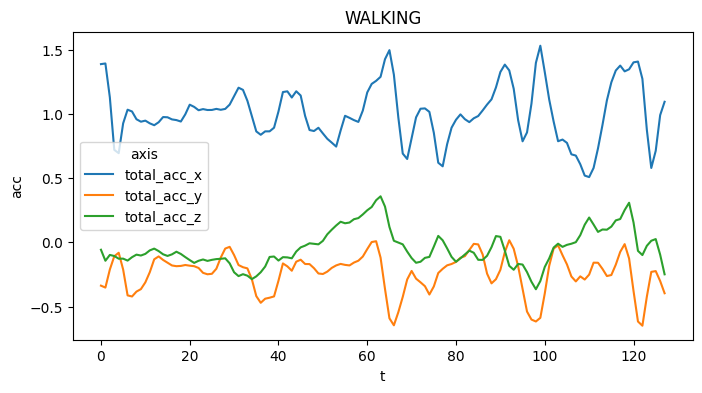

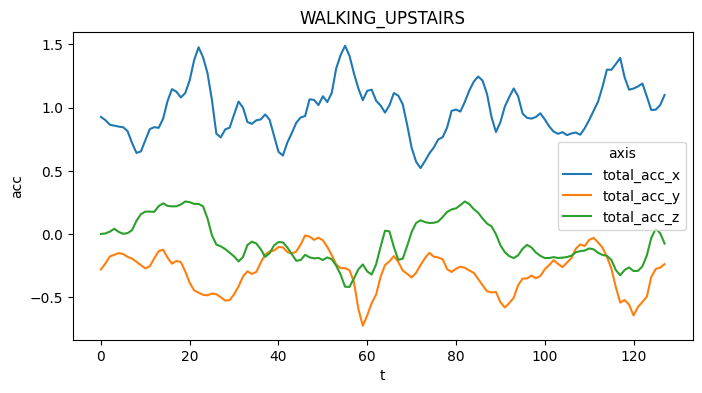

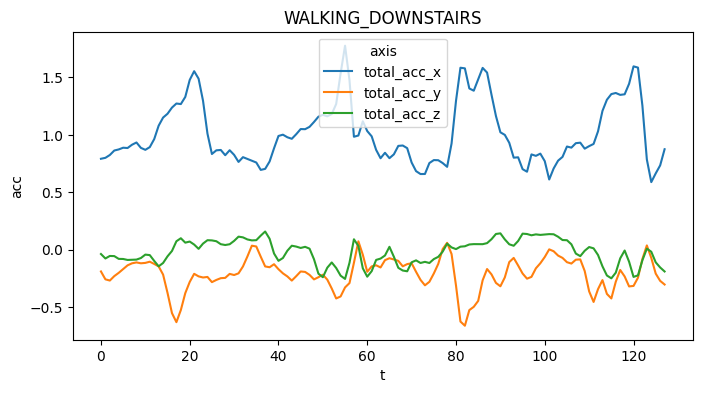

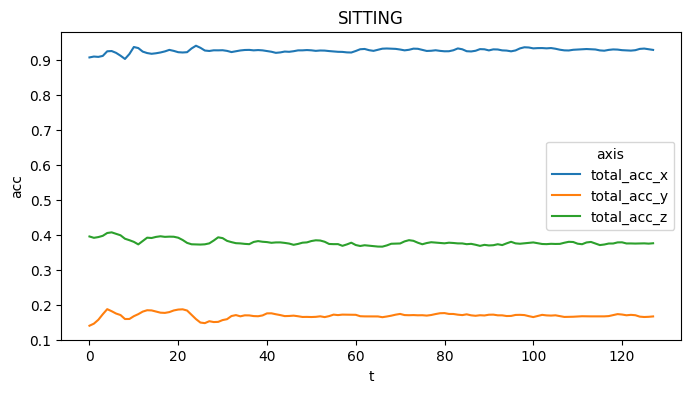

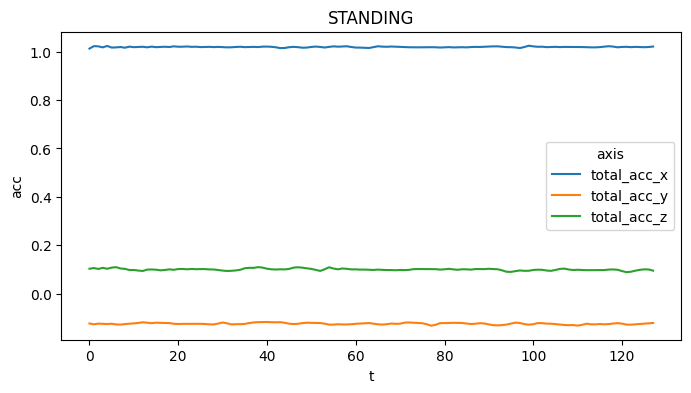

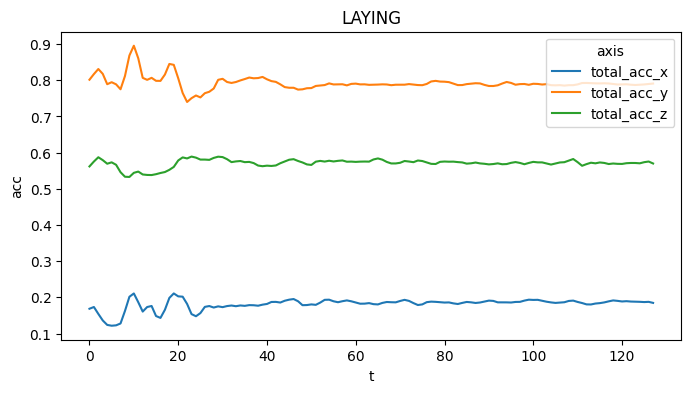

In [8]:
# code here
df_train["sample_id"] = df_train.index // 128        # 이미 있으면 생략
df_total = df_train[["sample_id", "t", "activity", "total_acc_x", "total_acc_y", "total_acc_z"]]

df_long = df_total.melt(
    id_vars=["sample_id", "t", "activity"],
    value_vars=["total_acc_x", "total_acc_y", "total_acc_z"],
    var_name="axis", value_name="acc",
)

import seaborn as sns
for l in LABELS:
    d = df_long[df_long["activity"] == l]
    d = d[d["sample_id"] == d["sample_id"].iloc[0]]   # 그 행동의 첫 샘플 1개만
    plt.figure(figsize=(8, 4))
    sns.lineplot(data=d, x="t", y="acc", hue="axis")
    plt.title(l)
    plt.show()

**Q2. 행동별로 총가속도(total_acc)의 x, y, z를 선그래프로 그려 보세요.**

- smaple id, t, activity, total_acc_x, total_acc_y, total_acc_z에 대한 long form data가 필요하니다.

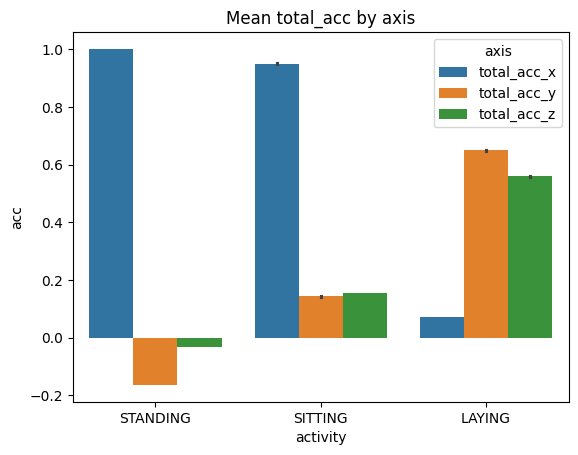

In [9]:
static = ["SITTING", "STANDING", "LAYING"]
d = df_long[df_long["activity"].isin(static)]
sns.barplot(data=d, x="activity", y="acc", hue="axis")
plt.title("Mean total_acc by axis")
plt.show()

## **4. 데이터 전처리하기**

### **4-1. 정규화**

**Q1. 채널별로 평균 0, 표준편차 1이 되도록 정규화하세요.**

- 센서마다 값의 크기가 다르기 때문입니다.
- 평균과 표준편차는 **train 데이터로만** 계산하고, test에도 같은 값을 사용하세요.

In [10]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train.reshape(-1,9)).reshape(X_train.shape)
X_test_scaled = scaler.transform(X_test.reshape(-1,9)).reshape(X_test.shape)

In [11]:
print(X_train_scaled)

[[[ 4.19384101e-03  9.03318971e-02  5.22423267e-01 ...  5.02443254e-01
   -3.88680220e-01  4.59405147e-02]
  [ 5.52992821e-02  5.61293662e-02  5.18345296e-01 ...  5.26629865e-01
   -3.98038119e-01  5.36357127e-02]
  [ 5.08702248e-02  7.53194839e-02  4.55469429e-01 ...  5.24685860e-01
   -3.90693039e-01  4.36161198e-02]
  ...
  [-2.62350845e-03  3.78788123e-03  2.73502618e-02 ...  5.16033709e-01
   -3.90861571e-01  3.88160720e-02]
  [ 2.12494400e-03  1.52455792e-02  2.48539113e-02 ...  5.18272221e-01
   -3.87474060e-01  3.73859704e-02]
  [ 1.13515249e-02  2.74651218e-02 -1.86609272e-02 ...  5.22616386e-01
   -3.83844614e-01  2.37287059e-02]]

 [[ 8.87907390e-03 -3.59011814e-02 -2.48732582e-01 ...  5.17014205e-01
   -3.90622199e-01  3.19523811e-02]
  [ 2.66177952e-02 -5.87743632e-02 -2.32254758e-01 ...  5.25535941e-01
   -3.97864699e-01  3.59250046e-02]
  [ 1.80422999e-02 -6.64695054e-02 -2.40459651e-01 ...  5.21674812e-01
   -4.00367051e-01  3.24673243e-02]
  ...
  [-2.05795038e-02 -4.2

### **4-2. DataLoader 만들기**

**Q1. 정규화한 데이터를 텐서로 바꾸고, 배치 크기 64의 DataLoader를 만드세요.**

In [12]:
def make_loader(X, y, shuffle):
    ds = TensorDataset(torch.tensor(X), torch.tensor(y))
    return DataLoader(ds, batch_size=64, shuffle=shuffle)

train_loader = make_loader(X_train_scaled, y_train, shuffle=True)
test_loader  = make_loader(X_test_scaled,  y_test,  shuffle=False)

**Q2. 배치 하나를 꺼내서 shape을 확인하세요.**

In [13]:
xb, yb = next(iter(train_loader))
xb.shape, yb.shape

(torch.Size([64, 128, 9]), torch.Size([64]))

## **5. 모델링**

**Q1. RNN또는 STM 모델을 만들어 주세요.**
- 입력 -> RNN/LSTM -> 출력

In [14]:
class LSTM(nn.Module):
  def __init__(self):
    super().__init__()
    self.lstm = nn.LSTM(9, 64, batch_first=True)
    self.fc = nn.Linear(64, 6)

  def forward(self, x):
    h, _ = self.lstm(x)
    return self.fc(h[:,-1,:])

**Q2. 모델을 생성하고, 출력하여 층 구조를 출력해봅니다.**

In [15]:
lstm = LSTM().to(device)
print(lstm)

LSTM(
  (lstm): LSTM(9, 64, batch_first=True)
  (fc): Linear(in_features=64, out_features=6, bias=True)
)


## **6. 모델 학습**

**Q1. 정확도를 계산하는 evaluate 함수를 만드세요.**

In [16]:
def evaluate(model):
    model.eval()
    correct, total = 0, 0
    with torch.no_grad():
        for xb, yb in test_loader:
            xb, yb = xb.to(device), yb.to(device)
            pred = model(xb).argmax(dim=1)
            correct += (pred == yb).sum().item()
            total += len(yb)
    return correct / total

**Q2. 학습을 진행하는 train 함수를 만드세요.**
- 모델, epochs, learning rate를 파라미터로 받아줍니다.
- 손실 함수 : CrossEntropyLoss
- 최적화 : Adam
- learning rate : 0.001
- epochs : 50

loss와 accuracy 대한 결과를 리스트에 저장하여 return합니다.

In [17]:
learning_rate = 0.001
epochs=50

def train(model, epochs, lr):
  optimizer = torch.optim.Adam(model.parameters(), lr=lr)
  criterion = nn.CrossEntropyLoss()
  losses = []
  acc = []
  for epoch in range(epochs):
    model.train()
    loss_sum = 0
    for xb, yb in train_loader:
      xb, yb = xb.to(device), yb.to(device)
      optimizer.zero_grad()
      loss = criterion(model(xb), yb)
      loss.backward()
      optimizer.step()
      loss_sum += loss.item() * len(yb)
    losses.append(loss_sum / len(train_loader.dataset))
    acc.append(evaluate(model))
    if (epoch+1) % 10 == 0:
      print(f"epoch {epoch+1:2d} | loss {loss_sum / len(train_loader.dataset):.4f}")
  return losses, acc

**Q3. 모델을 학습시킵니다.**
- 그리고 loss와 accuracy를 저장합니다.

In [18]:
lstm_loss, lstm_acc = train(lstm, epochs, learning_rate)

epoch 10 | loss 0.1454
epoch 20 | loss 0.1287
epoch 30 | loss 0.1095
epoch 40 | loss 0.1045
epoch 50 | loss 0.1149


In [19]:
lstm_accuracy = evaluate(lstm)
print(lstm_accuracy)

0.8680013573125213


## **7. 모델 평가**

**Q1. 모델의 train loss와 test 정확도를 각각 그래프로 비교하세요.**

그리고 이 그래프로 알 수 있는 정보를 코드 아래 적어 주세요.

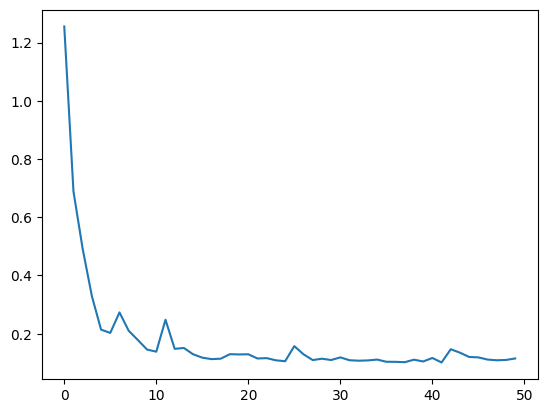

In [21]:
plt.plot(lstm_loss)
plt.show()

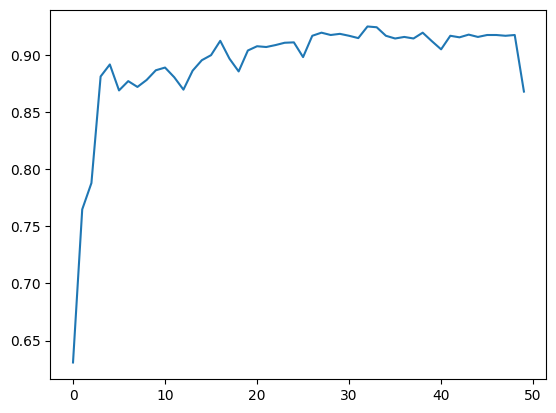

In [22]:
plt.plot(lstm_acc)
plt.show()

**Q2. RNN과 LSTM 모델의 혼동 행렬(confusion matrix)을 그려 보세요.**

- 행은 실제 행동, 열은 예측한 행동입니다.
- 대각선 바깥의 숫자가 클수록 그 두 행동을 자주 헷갈렸다는 뜻입니다.

In [23]:
lstm.eval()
with torch.no_grad():
    logits = lstm(torch.tensor(X_test_scaled).to(device))     # (2947, 6)
pred_lstm = logits.argmax(dim=1).cpu().numpy()                # (2947,)

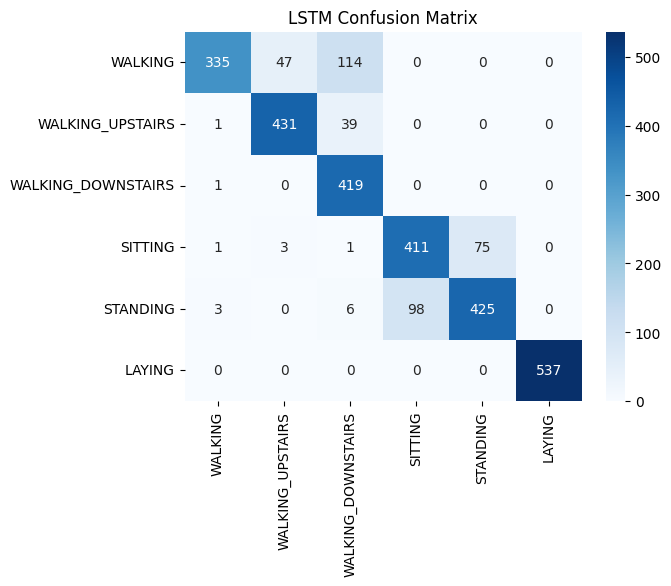

In [24]:
from sklearn.metrics import confusion_matrix

plt.title("LSTM Confusion Matrix")
sns.heatmap(confusion_matrix(y_test, pred_lstm), annot=True, cmap="Blues", fmt="1.0f",
            xticklabels=LABELS, yticklabels=LABELS)
plt.show()

## **8. 예측하기**

**Q1. 테스트 데이터에서 아무 데이터를 하나 선정하여, 결과를 예측해봅시다.**
- 예측을 위해서는 lstm또는 rnn에서 나온 결과를 softmax 활성화 함수로 넘겨줘야 다중 분류의 결과를 볼 수 있습니다.

정답: SITTING
예측: STANDING (88.3%)


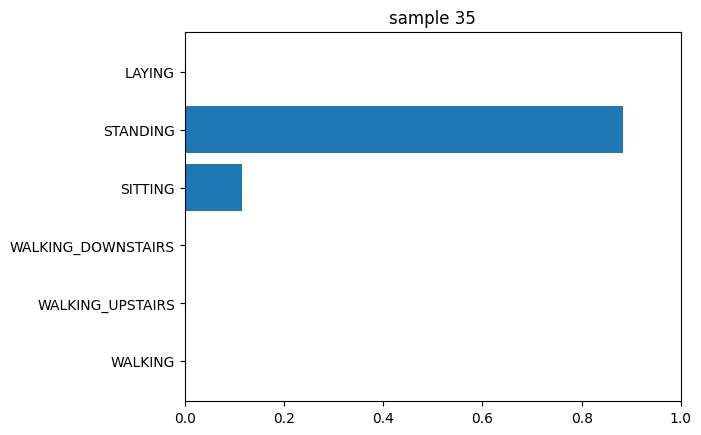

In [25]:
import torch.nn.functional as F

idx = 35
x = torch.tensor(X_test_scaled[idx:idx+1]).to(device)       # (1, 128, 9)
lstm.eval()
with torch.no_grad():
    prob = F.softmax(lstm(x), dim=1)[0].cpu().numpy()       # (6,)

print("정답:", LABELS[y_test[idx]])
print("예측:", LABELS[prob.argmax()], f"({prob.max():.1%})")
plt.barh(LABELS, prob); plt.xlim(0, 1); plt.title(f"sample {idx}")
plt.show()

## **9. 머신러닝 모델과 비교하기**

**Q1. 아무 머신 러닝 모델을 활용하여 현재 데이터를 학습시키고, 평가한 후 결과를 비교해 봅시다.**

In [48]:
from sklearn.linear_model import LogisticRegression

lr = LogisticRegression()
lr.fit(X_train_scaled.reshape((len(X_train_scaled), -1)), y_train)

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


LogisticRegression()

In [49]:
pred = lr.predict(X_test_scaled.reshape((len(X_test_scaled), -1)))

In [50]:
from sklearn.metrics import accuracy_score, confusion_matrix

print(accuracy_score(y_test, pred))

0.5816084153376315


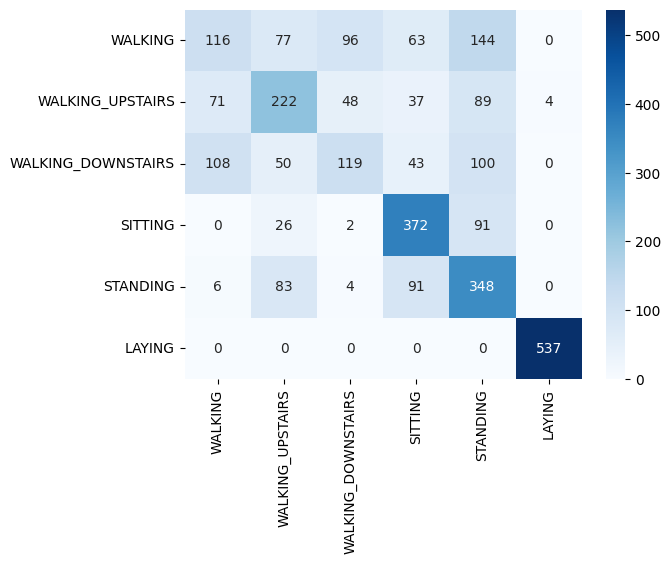

In [51]:
sns.heatmap(confusion_matrix(y_test, pred), annot=True, cmap="Blues", fmt="1.0f",
            xticklabels=LABELS, yticklabels=LABELS)
plt.show()